In [14]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.data import build_beat_table, load_beats
from src.segment import build_dataset

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
df, dropped_q = build_beat_table()
print('beats kept:', len(df), '| Q beats dropped:', dropped_q)

beats kept: 100718 | Q beats dropped: 15


In [16]:
assert not set(C.PACED) & set(df.record)
assert not set(C.DS1_PRIMARY) & set(C.DS2_PRIMARY)
assert df.record.nunique() == 44
assert len(C.DS1_PRIMARY) == 23 and len(C.DS2_PRIMARY) == 21
assert (df.aami == 'F').sum() == 803 and (df.aami == 'S').sum() == 2781
print('all checks passed')

all checks passed


In [17]:
print(pd.crosstab(df.split, df.aami, margins=True)[C.CLASSES + ['All']])
print(pd.crosstab(df.split_orig, df.aami, margins=True)[C.CLASSES + ['All']])

aami       N     S     V    F     All
split                                
DS1    47927   999  3807  416   53149
DS2    42198  1782  3202  387   47569
All    90125  2781  7009  803  100718
aami            N     S     V    F     All
split_orig                                
DS1         45866   944  3788  415   51013
DS2         44259  1837  3221  388   49705
All         90125  2781  7009  803  100718


In [18]:
t = pd.crosstab([df.split, df.record], df.aami)[C.CLASSES]
display(t)
for sp in ['DS1', 'DS2']:
    s = t.loc[sp]
    print(sp, 'top-record share:', (s.max() / s.sum()).round(2).to_dict())
    print(sp, 'records with >=20 beats:', (s >= 20).sum().to_dict())
print(t.loc['DS1'].idxmax().to_dict(), t.loc['DS2'].idxmax().to_dict())

aami             N     S    V    F
split record                      
DS1   101     1860     3    0    0
      106     1507     0  520    0
      108     1740     4   17    2
      109     2492     0   38    2
      112     2537     2    0    0
      114     1820    12   43    4
      115     1953     0    0    0
      116     2302     1  109    0
      118     2166    96   16    0
      119     1543     0  444    0
      122     2476     0    0    0
      124     1536    31   47    5
      201     1635   128  198    2
      202     2061    55   19    1
      203     2529     2  444    1
      205     2571     3   71   11
      207     1543   107  210    0
      208     1586     2  992  373
      209     2621   383    1    0
      215     3195     3  164    1
      220     1954    94    0    0
      223     2045    73  473   14
      230     2255     0    1    0
DS2   100     2239    33    1    0
      103     2082     2    0    0
      105     2526     0   41    0
      111     2123     0    1    0
      113     1789     6    0    0
      117     1534     1    0    0
      121     1861     1    1    0
      123     1515     0    3    0
      200     1743    30  826    2
      210     2423    22  195   10
      212     2748     0    0    0
      213     2641    28  220  362
      214     2003     0  256    1
      219     2082     7   64    1
      221     2031     0  396    0
      222     2274   209    0    0
      228     1688     3  362    0
      231     1568     1    2    0
      232      398  1382    0    0
      233     2230     7  831   11
      234     2700    50    3    0

DS1 top-record share: {'N': 0.07, 'S': 0.38, 'V': 0.26, 'F': 0.9}
DS1 records with >=20 beats: {'N': 23, 'S': 8, 'V': 13, 'F': 1}
DS2 top-record share: {'N': 0.07, 'S': 0.78, 'V': 0.26, 'F': 0.94}
DS2 records with >=20 beats: {'N': 21, 'S': 7, 'V': 9, 'F': 1}
{'N': 215, 'S': 209, 'V': 208, 'F': 208} {'N': 212, 'S': 232, 'V': 233, 'F': 213}


(53138, 180) (53138, 4) [47917   999  3807   415]


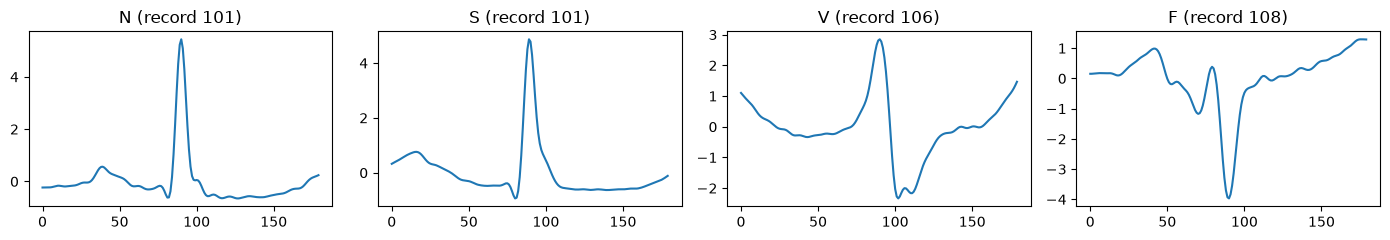

In [20]:
d1 = df[df.split == 'DS1']
X, RR, y, rec, ridx = build_dataset(d1)
fig, ax = plt.subplots(1, 4, figsize=(14, 2.5))
for k, c in enumerate(C.CLASSES):
    i = np.where(y == k)[0][0]
    ax[k].plot(X[i]); ax[k].set_title(f'{c} (record {rec[i]})')
plt.tight_layout()
print(X.shape, RR.shape, np.bincount(y))

In [21]:
d2 = df[df.split == 'DS2']
print(d2[d2.aami == 'N'].groupby(['record', 'symbol']).size().unstack(fill_value=0).to_string())

symbol     L     N     R    j
record                       
100        0  2239     0    0
103        0  2082     0    0
105        0  2526     0    0
111     2123     0     0    0
113        0  1789     0    0
117        0  1534     0    0
121        0  1861     0    0
123        0  1515     0    0
200        0  1743     0    0
210        0  2423     0    0
212        0   923  1825    0
213        0  2641     0    0
214     2003     0     0    0
219        0  2082     0    0
221        0  2031     0    0
222        0  2062     0  212
228        0  1688     0    0
231        0   314  1254    0
232        0     0   397    1
233        0  2230     0    0
234        0  2700     0    0
